# 02 · Scalanie danych (merging_data): Trump → media → rynek (2018-2019)

Ten notebook **łączy czyste pliki** z `clean_out/` (wynik `run_cleaning` z notebooka eksploracji) w tabele analityczne.
Tylko **fakty**: czas publikacji, liczności, ceny. Bez sentymentu, tonu i ram narracyjnych.

**Jak łączymy:** nie przez klucz, tylko przez oś czasu UTC. Zdarzenie ma moment `t`; odpowiedź mediów liczymy w oknie `(t, t+h]`,
rynku jako `log P(t+h)/P(t)`, gdzie `P(t)` to cena otwarcia ostatniej świecy 5-min rozpoczętej ≤ `t`. Kontrola: 20 losowych chwil
o tym samym dniu tygodnia i godzinie NY (placebo), losowanych osobno dla każdego rodzaju zdarzeń.

**Kolejność:** 1) `01_cleaning.ipynb` → 2) ten notebook → 3) `03_annotation.ipynb`. Wyniki trafiają do `clean_out/merged/`, slajdy do `slajdy/`.

In [1]:
import os, sys, types, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)

PROJECT_DIR = None   # opcjonalnie ścieżka do folderu projektu (tego z cleaning_data/ i merging_data/); None = szukaj

def find_project():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / "cleaning_data" / "__init__.py").exists() and (d / "merging_data" / "__init__.py").exists():
            return d
    return None

root = Path(PROJECT_DIR) if PROJECT_DIR else find_project()
if root is None:
    raise SystemExit(f"Nie znaleziono folderu projektu z cleaning_data/ i merging_data/ (katalog roboczy: {Path.cwd()}). "
                     "Ustaw PROJECT_DIR.")
os.chdir(root)                                   # ścieżki danych (clean_out/, data/, ...) są względem folderu projektu
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
for m in [m for m in sys.modules if m.split(".")[0] in ("cleaning_data", "merging_data", "annotation", "explore_pkg")]:
    del sys.modules[m]                           # świeże wczytanie po podmianie plików (bez restartu kernela)
import cleaning_data, merging_data
PACKAGES = [cleaning_data, merging_data]
pkg = types.SimpleNamespace(**{k: getattr(p, k) for p in PACKAGES for k in p.__all__})
print("Projekt:", root)

cfg = pkg.Config()                    # te same ścieżki co w notebooku 01 (clean_out, gdelt_data/gkg, ...)
show = pkg.show
print("Okres:", cfg.periods, "| horyzonty:", list(cfg.horizons))

Projekt: C:\Users\pauko\Desktop\Studia\Magisterka\2 semestr\Analiza mediów cyfrowych\Laby\tariffs-vs-social-media
Okres: {'2018-2019': ('2018-01-01', '2019-12-31')} | horyzonty: ['1m', '5m', '1h', '3h', '1d', '3d', '7d']


## 1. Co jest do scalenia
Pliki po czyszczeniu i paczki GKG (mianownik stawek). Brak pliku źródła nie zatrzymuje scalenia; brak postów Trumpa tak.

In [2]:
L = pkg.CleanLoader(cfg)
show(L.inventory(), "inwentarz czystych plików")


=== inwentarz czystych plików ===


,źródło,plik,istnieje,MB,pliki
0,Trump,clean_out\trump\trump_clean.csv,True,2.40,NaN
1,FNSPID,clean_out\fnspid\fnspid_clean.csv,True,0.26,NaN
2,GKG,clean_out\gkg\gkg_clean.csv,True,15.44,NaN
3,GTA,clean_out\gta\gta_clean.csv,True,0.09,NaN
4,Federal Register,clean_out\federal_register\fr_clean.csv,True,0.09,NaN
5,Rynek: S&P 500,clean_out\market\S_P_500_mid.csv,True,9.32,NaN
6,Rynek: Nasdaq,clean_out\market\Nasdaq_mid.csv,True,9.41,NaN
7,Rynek: Hang Seng,clean_out\market\Hang_Seng_mid.csv,True,4.72,NaN
8,Rynek: EURUSD,clean_out\market\EURUSD_mid.csv,True,12.11,NaN
9,Rynek: TLT,clean_out\market\TLT_mid.csv,True,2.92,NaN


## 2. Scalenie
`build_merged` buduje zdarzenia, okna mediów, reakcje rynku z kontrolą placebo i panele czasowe, a potem zapisuje wszystko do `clean_out/merged/`.
Na pełnych danych trwa od kilkudziesięciu sekund do kilku minut (placebo dla każdego zdarzenia × instrumentu).

In [3]:
GAP = "6h"      # przerwa, po której zaczyna się nowy epizod tweetów
K   = 20        # ile chwil kontrolnych na zdarzenie

res = pkg.build_merged(cfg, gap=GAP, k=K, seed=0)
show(pkg.EventBuilder.summary(res["events"]), "zdarzenia")
show(res["sources"], "wczytane źródła (wiersze)")
print("Zapisano do:", res["out_dir"])


=== zdarzenia ===


,zdarzenia,od,do,precyzja,wątek_top
kind,,,,,
fr,56,2018-03-19 00:00:00+00:00,2019-12-30 00:00:00+00:00,day,USA-Chiny
fr_effective,6,2018-03-19 00:00:00+00:00,2019-12-15 00:00:00+00:00,day,Stal/aluminium
gta_announced,75,2018-01-10 00:00:00+00:00,2019-12-26 00:00:00+00:00,day,wielostronne
gta_implemented,68,2018-03-12 00:00:00+00:00,2019-12-26 00:00:00+00:00,day,wielostronne
trump_episode,298,2018-01-02 14:08:56+00:00,2019-12-31 14:16:40+00:00,exact,USA-Chiny
trump_post,475,2018-01-02 14:08:56+00:00,2019-12-31 14:16:40+00:00,exact,USA-Chiny



=== wczytane źródła (wiersze) ===
trump: 7914
fnspid: 847
gkg: 24605
gkg_files: 296
gta: 185
fr: 103
instrumenty: ['S&P 500', 'Nasdaq', 'Hang Seng', 'EURUSD', 'TLT']
Zapisano do: clean_out\merged


## 3. Testy poprawności
Niezależne od kodu scalającego: okna tweetów i FNSPID oraz zwroty są tu przeliczane wprost pętlą i porównywane z wynikiem.
`BŁĄD` zatrzymuje notebook (złamany niezmiennik, np. wyciek z przyszłości). `UWAGA` to ograniczenie danych do opisania, nie błąd kodu.

In [4]:
checks = pkg.check_merged(res, strict=True)
print(checks["wynik"].value_counts().to_dict())


=== TESTY SCALENIA ===


,test,wynik,szczegóły
0,event_id unikalne,OK,978 zdarzeń
1,wszystkie zdarzenia w okresie badania,OK,2018-01-02 14:08:56+00:00 .. 2019-12-31 14:16:40+00:00
2,brak NaT w czasie zdarzeń,OK,
3,tabela zdarzeń 1:1 po scaleniu,OK,978 wierszy
4,epizody rozdzielone przerwą >= gap,OK,najkrótsza przerwa 0 days 06:01:28
5,suma postów w epizodach = liczba postów,OK,475 vs 475
6,market_long: zdarzenie x instrument x horyzont,OK,"34,230 = 978 x 5 x 7"
7,zdarzenia dzienne: horyzonty < 1d puste,OK,
8,rynek zamknięty w t: horyzonty < 1d puste,OK,"6,236 wierszy"
9,kontrole placebo: zróżnicowane (>=50% unikalnych) i liczne (>=5/zdarzenie),OK,"fr: 15.0/zd., unikalne 87%; fr_effective: 10.7/zd., unikalne 98%; gta_announ..."


{'OK': 29, 'UWAGA': 1}


## 3b. Wiarygodność DANYCH (nie kodu)
Testy z sekcji 3 dowodzą, że scalanie jest poprawne mechanicznie. Nie mówią, czy dane źródłowe są prawdziwe i trafne. Tu pięć kontroli
z niezależnymi punktami odniesienia: czas zaszyty w ID tweeta, ręczna próbka słownika ceł, znane zamknięcia S&P 500, dziury w pokryciu, szum w GTA.

In [5]:
# KONTROLA WIARYGODNOŚCI DANYCH (testy w sekcji 3 sprawdzają KOD scalania; te sprawdzają same DANE)
import numpy as np, pandas as pd
tr, ev, T = pkg.CleanLoader(cfg).trump(), res["events"], res["trading"]

# 1) Czas tweetów vs czas zaszyty w ID tweeta (Twitter "snowflake": niezależne źródło prawdy o czasie UTC)
ms = tr["post_id"].map(lambda s: (int(s) >> 22) + 1288834974657 if str(s).isdigit() and int(s) > 2**40 else np.nan)
diff = (tr["time_utc"] - pd.to_datetime(ms, unit="ms", utc=True)).dt.total_seconds().abs()
print(f"1) czas tweetów: {100 * (diff <= 1).mean():.2f}% zgodnych z ID co do 1 s (max różnica {diff.max():.0f} s)")

# 2) Trafność słownika ceł: ile postów-zdarzeń przechodzi też ścisły słownik + losowa próbka do przeczytania
p = res["posts"]
strict = p["relevant_strict"].mean() if "relevant_strict" in p else np.nan
print(f"2) posty o cłach: {len(p)}; z nich ścisły słownik (relevant_strict): {100 * strict:.0f}%. Przeczytaj próbkę poniżej:")
show(p.sample(min(25, len(p)), random_state=1)[["time_utc", "thread", "relevant_strict", "text"]].sort_values("time_utc"))

# 3) Rynek vs znane zamknięcia S&P 500 (zmiana dzienna indeksu kasowego, %); CFD + klucz eff_day => tolerancja 0,6 pp
ref = {"2018-02-05": -4.10, "2018-10-10": -3.29, "2018-12-26": 4.96, "2019-05-13": -2.41, "2019-08-05": -2.98, "2019-08-23": -2.59}
if "S_P_500_ret" in T:
    chk = pd.DataFrame({"S&P 500 (źródło, %)": pd.Series(ref)})
    chk.index = pd.to_datetime(chk.index)
    chk["nasze dane (%)"] = 100 * (np.exp(T["S_P_500_ret"].reindex(chk.index)) - 1)
    chk["zgodne"] = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs() <= 0.6
    show(chk.round(2), "3) dni o znanych dużych ruchach S&P 500")

# 4) Pokrycie mediów w czasie: czy FNSPID i GKG nie mają dziur (miesiące bez danych)
D = res["daily"]
cov = pd.DataFrame({"tweety o cłach": D["tw_topic_n"], "FNSPID": D.get("fn_n", np.nan),
                    "GKG paczki": D.get("gkg_files_n", np.nan)}).resample("MS").sum()
cov.index = cov.index.strftime("%Y-%m")
show(cov.T.astype(int), "4) liczności miesięczne (0 w FNSPID/GKG = brak danych albo brak tematu: sprawdź)")

# 5) GTA: czy zdarzenia to wojna handlowa, czy drobne reklasyfikacje taryf
g = ev[ev["kind"] == "gta_announced"]
show(g["thread"].value_counts().to_frame("zdarzenia"), "5a) GTA: wątki (po poprawce: priorytet USA-Chiny, >=3 regiony = wielostronne)")
show(g.sort_values("weight", ascending=False)[["eff_day", "thread", "weight", "title"]].head(10), "5b) GTA: największe wg liczby produktów")
print(f"5c) GTA ogłoszenia z < 5 produktami: {100 * (g['weight'].fillna(0) < 5).mean():.0f}% (kandydaci na szum)")


1) czas tweetów: 98.00% zgodnych z ID co do 1 s (max różnica 43201 s)
2) posty o cłach: 475; z nich ścisły słownik (relevant_strict): 83%. Przeczytaj próbkę poniżej:


,time_utc,thread,relevant_strict,text
4,2018-03-02 10:50:34+00:00,inne,True,When a country (USA) is losing many billions of dollars on trade with virtua...
31,2018-04-08 12:12:35+00:00,USA-Chiny,True,"President Xi and I will always be friends, no matter what happens with our d..."
47,2018-05-15 18:39:58+00:00,inne,True,Today is one of the most important and solemn occasions of the year – the da...
139,2018-09-18 12:50:29+00:00,USA-Chiny,False,China has openly stated that they are actively trying to impact and change o...
159,2018-11-07 11:21:51+00:00,inne,True,"Received so many Congratulations from so many on our Big Victory last night,..."
162,2018-11-15 20:43:42+00:00,inne,True,It is our sacred duty to support America’s Service Members every single day ...
172,2018-12-04 14:30:16+00:00,USA-Chiny,False,"The negotiations with China have already started. Unless extended, they will..."
179,2018-12-07 00:56:18+00:00,USA-Chiny,False,Statement from China: “The teams of both sides are now having smooth communi...
197,2019-01-08 13:16:09+00:00,USA-Chiny,False,Talks with China are going very well!
204,2019-01-30 11:02:54+00:00,inne,True,Maduro willing to negotiate with opposition in Venezuela following U.S. sanc...



=== 3) dni o znanych dużych ruchach S&P 500 ===


,"S&P 500 (źródło, %)",nasze dane (%),zgodne
2018-02-05,-4.10,-4.15,True
2018-10-10,-3.29,-3.25,True
2018-12-26,4.96,5.45,True
2019-05-13,-2.41,-2.46,True
2019-08-05,-2.98,-2.95,True
2019-08-23,-2.59,-2.58,True



=== 4) liczności miesięczne (0 w FNSPID/GKG = brak danych albo brak tematu: sprawdź) ===


day,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10,2018-11,2018-12,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,2019-09,2019-10,2019-11,2019-12
tweety o cłach,3,0,20,16,22,29,20,19,16,13,10,23,19,9,6,10,63,40,19,34,28,20,12,24
FNSPID,18,9,56,22,35,35,35,12,20,18,17,15,13,18,14,28,135,98,16,104,38,35,21,30
GKG paczki,0,0,73,0,0,0,73,0,0,0,0,0,0,0,0,0,75,0,17,58,0,0,0,0



=== 5a) GTA: wątki (po poprawce: priorytet USA-Chiny, >=3 regiony = wielostronne) ===


,zdarzenia
thread,
wielostronne,50
USA-Chiny,14
inne,5
UE,3
Japonia/Korea/Indie,2
Meksyk/Kanada,1



=== 5b) GTA: największe wg liczby produktów ===


,eff_day,thread,weight,title
302,2018-09-18,USA-Chiny,3853.0,CHN: China: Third batch of retaliatory tariffs hit $60bn of US imports to China
764,2019-08-23,USA-Chiny,3619.0,CHN: China: New round of retaliatory tariffs on US imports worth $75bn
560,2019-05-13,USA-Chiny,3495.0,CHN: China: Supplementary tariffs on US imports raised in retaliation
53,2018-03-29,inne,2712.0,USA: United States of America: Suspension of Rwanda’s apparel trade preferen...
470,2019-03-04,Japonia/Korea/Indie,2476.0,USA: United States of America: Termination of trade preferences for India an...
364,2018-11-29,wielostronne,1967.0,CHN: China: Further relaxation of import taxes on certain cross-border trans...
317,2018-09-30,wielostronne,1122.0,"CHN: China: Import tariffs on over 1,500 items cut"
24,2018-03-08,USA-Chiny,1080.0,USA: United States of America: Tariffs on steel imports under the national s...
137,2018-05-31,wielostronne,1012.0,"CHN: China: Tariffs on 1,449 items cut"
931,2019-12-11,wielostronne,854.0,CHN: China: Customs ministry announces new tax-free import policy


5c) GTA ogłoszenia z < 5 produktami: 44% (kandydaci na szum)


## 4. Tabela zdarzeń (jeden wiersz na zdarzenie)
Zdarzenie + wolumeny mediów przed/po + zwroty i nadwyżki nad placebo dla każdego instrumentu i horyzontu.

In [6]:
T = res["event_table"]
print(T.shape)
show(T.head(5), "event_table: pierwsze wiersze")
groups = {"zdarzenie": [c for c in res["events"].columns],
          "FNSPID (dni)": [c for c in T if c.startswith("fn_")],
          "Twitter (kolejne tweety)": [c for c in T if c.startswith("tw_")],
          "GKG (stawka na paczkę)": [c for c in T if c.startswith("gkg_")],
          "rynek": [c for c in T if any(c.startswith(pkg.tag_of(i) + "_") for i in res["prices"])]}
show({k: f"{len(v)} kolumn, np. {v[:3]}" for k, v in groups.items()}, "grupy kolumn")

(978, 245)

=== event_table: pierwsze wiersze ===


,event_id,kind,t,precision,date_source,eff_day,thread,threads,weight,n_posts,favs,rts,session,ny_hour,title,ref_id,fn_n_post_1d,fn_n_pre_1d,fn_all_n_post_1d,fn_all_n_pre_1d,fn_sector_n_post_1d,fn_sector_n_pre_1d,fn_th_Japonia_Korea_Indie_n_post_1d,fn_th_Japonia_Korea_Indie_n_pre_1d,fn_th_Meksyk_Kanada_n_post_1d,fn_th_Meksyk_Kanada_n_pre_1d,fn_th_UE_n_post_1d,fn_th_UE_n_pre_1d,fn_th_USA_Chiny_n_post_1d,fn_th_USA_Chiny_n_pre_1d,...,S_P_500_pre_ret_3d,S_P_500_pre_ret_7d,Nasdaq_pre_ret_1m,Nasdaq_pre_ret_5m,Nasdaq_pre_ret_1h,Nasdaq_pre_ret_3h,Nasdaq_pre_ret_1d,Nasdaq_pre_ret_3d,Nasdaq_pre_ret_7d,Hang_Seng_pre_ret_1m,Hang_Seng_pre_ret_5m,Hang_Seng_pre_ret_1h,Hang_Seng_pre_ret_3h,Hang_Seng_pre_ret_1d,Hang_Seng_pre_ret_3d,Hang_Seng_pre_ret_7d,EURUSD_pre_ret_1m,EURUSD_pre_ret_5m,EURUSD_pre_ret_1h,EURUSD_pre_ret_3h,EURUSD_pre_ret_1d,EURUSD_pre_ret_3d,EURUSD_pre_ret_7d,TLT_pre_ret_1m,TLT_pre_ret_5m,TLT_pre_ret_1h,TLT_pre_ret_3h,TLT_pre_ret_1d,TLT_pre_ret_3d,TLT_pre_ret_7d
0,ep_948194400114487296,trump_episode,2018-01-02 14:08:56+00:00,exact,exact,2018-01-02,Japonia/Korea/Indie,Japonia/Korea/Indie,65372.0,1.0,65372.0,13491.0,przed_otwarciem,9.0,Sanctions and “other” pressures are beginning to have a big impact on North ...,948194400114487296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000171,0.00014,0.003586,NaN,NaN,NaN,NaN,0.000148,-0.000148,0.000492,NaN,NaN,NaN,NaN,-0.000328,-0.000746,-0.000999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tw_948194400114487296,trump_post,2018-01-02 14:08:56+00:00,exact,exact,2018-01-02,Japonia/Korea/Indie,Japonia/Korea/Indie,65372.0,1.0,65372.0,13491.0,przed_otwarciem,9.0,Sanctions and “other” pressures are beginning to have a big impact on North ...,948194400114487296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000171,0.00014,0.003586,NaN,NaN,NaN,NaN,0.000148,-0.000148,0.000492,NaN,NaN,NaN,NaN,-0.000328,-0.000746,-0.000999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gtaa_20180110_USA,gta_announced,2018-01-10 00:00:00+00:00,day,date_announced,2018-01-10,wielostronne,USA-Chiny|Meksyk/Kanada|UE|Japonia/Korea/Indie,2.0,2.0,NaN,NaN,NaN,NaN,USA: United States of America: Reclassification of girls’ upper body garment...,USA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.003793,0.021317,NaN,NaN,NaN,NaN,0.000404,0.00381,0.025367,NaN,NaN,NaN,NaN,0.003526,0.004141,0.014554,NaN,NaN,NaN,NaN,-0.003481,-0.008432,-0.011117,NaN,NaN,NaN,NaN,-0.013633,-0.014425,-0.013072
3,ep_951675713089888256,trump_episode,2018-01-12 04:42:25+00:00,exact,exact,2018-01-12,inne,inne,105248.0,1.0,105248.0,23922.0,po_sesji,23.0,The Democrats seem intent on having people and drugs pour into our country f...,951675713089888256,1.0,2.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.000021,0.000100,-0.000303,0.008648,0.006695,-0.001928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,tw_951675713089888256,trump_post,2018-01-12 04:42:25+00:00,exact,exact,2018-01-12,inne,inne,105248.0,1.0,105248.0,23922.0,po_sesji,23.0,The Democrats seem intent on having people and drugs pour into our country f...,951675713089888256,1.0,2.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.000021,0.000100,-0.000303,0.008648,0.006695,-0.001928,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== grupy kolumn ===
zdarzenie: 16 kolumn, np. ['event_id', 'kind', 't']
FNSPID (dni): 54 kolumn, np. ['fn_n_post_1d', 'fn_n_pre_1d', 'fn_all_n_post_1d']
Twitter (kolejne tweety): 10 kolumn, np. ['tw_n_post_1h', 'tw_n_pre_1h', 'tw_n_post_3h']
GKG (stawka na paczkę): 25 kolumn, np. ['gkg_files_post_1h', 'gkg_rate_post_1h', 'gkg_files_pre_1h']
rynek: 140 kolumn, np. ['S_P_500_ret_1m', 'S_P_500_ret_5m', 'S_P_500_ret_1h']


**Pokrycie:** jaki % zdarzeń ma zwrot w danym horyzoncie (rynek otwarty w `t`, cena dostępna). Posty nocne i weekendowe dają puste horyzonty < 1d.

In [7]:
show(pkg.coverage_table(res), "pokrycie zwrotami [%]")


=== pokrycie zwrotami [%] ===


horizon                      1m    5m    1h    3h     1d     3d     7d
kind            instrument                                            
fr              S&P 500     0.0   0.0   0.0   0.0  100.0  100.0  100.0
                Nasdaq      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                Hang Seng   0.0   0.0   0.0   0.0   96.4   94.6   98.2
                EURUSD      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                TLT         0.0   0.0   0.0   0.0   96.4  100.0   98.2
fr_effective    S&P 500     0.0   0.0   0.0   0.0  100.0  100.0  100.0
                Nasdaq      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                Hang Seng   0.0   0.0   0.0   0.0  100.0  100.0  100.0
                EURUSD      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                TLT         0.0   0.0   0.0   0.0  100.0  100.0  100.0
gta_announced   S&P 500     0.0   0.0   0.0   0.0   98.7  100.0   98.7
                Nasdaq      0.0   0.0   0.0   0.0   98.7  100.0   98.7
                Hang Seng   0.0   0.0   0.0   0.0   97.3   98.7   98.7
                EURUSD      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                TLT         0.0   0.0   0.0   0.0   98.7   97.3   98.7
gta_implemented S&P 500     0.0   0.0   0.0   0.0  100.0  100.0   98.5
                Nasdaq      0.0   0.0   0.0   0.0  100.0  100.0   98.5
                Hang Seng   0.0   0.0   0.0   0.0  100.0  100.0   98.5
                EURUSD      0.0   0.0   0.0   0.0  100.0  100.0  100.0
                TLT         0.0   0.0   0.0   0.0  100.0  100.0   98.5
trump_episode   S&P 500     0.0  70.1  67.8  65.1   70.1   70.1   70.1
                Nasdaq      0.0  70.1  67.8  65.1   70.1   70.1   70.1
                Hang Seng   0.0  52.3  49.0  39.3   52.7   52.7   52.3
                EURUSD      0.0  76.2  75.8  75.2   76.5   76.5   76.5
                TLT         0.0  19.5  17.8  13.4   19.5   19.5   19.5
trump_post      S&P 500     0.0  73.1  70.9  67.6   73.1   73.1   73.1
                Nasdaq      0.0  73.1  70.9  67.6   73.1   73.1   73.1
                Hang Seng   0.0  57.3  54.3  42.1   57.5   57.5   57.3
                EURUSD      0.0  78.1  77.7  76.4   78.7   78.7   78.7
                TLT         0.0  21.9  20.2  15.8   21.9   21.9   21.9

## 5. Reakcja rynku: nadwyżka |zwrotu| nad placebo
CI 95% z bootstrapu klastrowego po dniach NY. Wartości w punktach bazowych (×10⁴).

In [8]:
for kind in ("trump_episode", "gta_announced", "gta_implemented", "fr"):
    x = pkg.excess_table(res, kind=kind)
    if len(x):
        x = x.assign(**{c: 1e4 * x[c] for c in ("mean", "lo", "hi", "ev_abs", "ctl_abs") if c in x})
        show(x.round(2), f"{kind}: nadwyżka |zwrotu| [pb]")


=== trump_episode: nadwyżka |zwrotu| [pb] ===


,instrument,horizon,n,n_dni,mean,ev_abs,ctl_abs,lo,hi,p_boot,istotne
0,EURUSD,5m,227,205,-0.11,1.75,1.86,-0.34,0.15,0.40,False
1,EURUSD,1h,226,204,-0.12,6.26,6.38,-0.93,0.76,0.78,False
2,EURUSD,3h,224,202,-0.21,11.23,11.44,-1.58,1.31,0.80,False
3,EURUSD,1d,227,205,0.25,27.47,27.22,-2.62,3.23,0.89,False
4,EURUSD,3d,227,205,-2.03,43.57,45.61,-6.20,2.12,0.34,False
5,EURUSD,7d,227,205,-3.05,64.43,67.48,-9.29,3.22,0.34,False
6,Hang Seng,5m,156,151,1.56,5.52,3.96,0.52,2.83,0.00,True
7,Hang Seng,1h,146,142,5.19,18.76,13.57,1.55,9.20,0.00,True
8,Hang Seng,3h,117,115,4.64,29.50,24.86,-0.95,11.12,0.11,False
9,Hang Seng,1d,157,152,6.66,85.96,79.30,-6.83,20.43,0.30,False



=== gta_announced: nadwyżka |zwrotu| [pb] ===


,instrument,horizon,n,n_dni,mean,ev_abs,ctl_abs,lo,hi,p_boot,istotne
0,EURUSD,1d,72,69,-2.05,28.95,30.99,-7.25,3.78,0.46,False
1,EURUSD,3d,72,69,-3.05,44.75,47.81,-12.23,7.06,0.53,False
2,EURUSD,7d,72,69,7.31,68.20,60.90,-5.67,21.22,0.27,False
3,Hang Seng,1d,52,50,5.42,92.90,87.48,-14.56,25.38,0.58,False
4,Hang Seng,3d,53,51,0.02,146.69,146.66,-36.84,39.72,0.90,False
5,Hang Seng,7d,53,51,0.27,179.54,179.27,-44.09,51.65,0.96,False
6,Nasdaq,1d,71,68,9.91,98.17,88.26,-12.83,35.13,0.43,False
7,Nasdaq,3d,72,69,2.44,143.85,141.40,-25.56,33.17,0.92,False
8,Nasdaq,7d,71,68,-25.59,163.94,189.53,-61.35,12.75,0.18,False
9,S&P 500,1d,71,68,7.61,73.16,65.55,-8.62,26.84,0.40,False



=== gta_implemented: nadwyżka |zwrotu| [pb] ===


,instrument,horizon,n,n_dni,mean,ev_abs,ctl_abs,lo,hi,p_boot,istotne
0,EURUSD,1d,60,57,-3.76,25.70,29.46,-9.67,2.30,0.25,False
1,EURUSD,3d,60,57,-14.38,35.88,50.26,-20.88,-7.75,0.00,True
2,EURUSD,7d,60,57,-5.67,59.44,65.11,-15.41,3.92,0.25,False
3,Hang Seng,1d,49,46,13.85,94.94,81.09,-8.25,38.21,0.27,False
4,Hang Seng,3d,49,46,15.43,142.50,127.06,-19.35,51.09,0.41,False
5,Hang Seng,7d,48,45,-6.62,185.72,192.34,-57.99,46.14,0.75,False
6,Nasdaq,1d,60,57,5.40,88.17,82.77,-14.76,27.23,0.62,False
7,Nasdaq,3d,60,57,-1.86,131.25,133.11,-30.10,29.82,0.89,False
8,Nasdaq,7d,59,56,17.41,195.29,177.88,-26.52,63.01,0.44,False
9,S&P 500,1d,60,57,3.83,62.43,58.60,-10.75,20.26,0.64,False



=== fr: nadwyżka |zwrotu| [pb] ===


,instrument,horizon,n,n_dni,mean,ev_abs,ctl_abs,lo,hi,p_boot,istotne
0,EURUSD,1d,56,50,-8.61,22.25,30.86,-13.44,-3.22,0.00,True
1,EURUSD,3d,56,50,-10.41,37.21,47.62,-18.55,-2.04,0.02,True
2,EURUSD,7d,56,50,-4.47,62.41,66.88,-16.47,7.54,0.43,False
3,Hang Seng,1d,40,36,13.80,96.36,82.56,-12.25,46.08,0.38,False
4,Hang Seng,3d,39,36,-8.24,135.97,144.20,-48.74,35.92,0.68,False
5,Hang Seng,7d,41,37,19.76,219.22,199.46,-31.28,73.98,0.48,False
6,Nasdaq,1d,56,50,-5.92,81.12,87.04,-27.42,17.45,0.58,False
7,Nasdaq,3d,56,50,8.76,136.51,127.75,-24.17,45.46,0.66,False
8,Nasdaq,7d,56,50,35.97,212.17,176.20,-8.87,89.08,0.14,False
9,S&P 500,1d,56,50,-3.99,58.78,62.76,-23.72,19.09,0.72,False


## 6. Panele do PCMCI+ i Local Projections
`trading` = dni handlowe (weekend doliczony do poniedziałku; liczniki i zwroty log sumowane). Liczniki: `_n`, zwroty: `_ret`, `_absret`, zmienność zrealizowana: `_rv`.
`gkg_files_n` = 0 oznacza **brak danych**, a nie brak artykułów (GKG to próbka paczek).

In [9]:
P = res["trading"]
print(P.shape, "|", P.index.min().date(), "..", P.index.max().date())
show(P.describe().T.round(4), "panel dni handlowych")
LagTools = pkg.LagTools
main = "S&P 500" if "S&P 500" in res["prices"] else list(res["prices"])[0]
tag = pkg.tag_of(main)
x, y = LagTools.prewhiten(P["tw_topic_n"]), LagTools.prewhiten(P[f"{tag}_absret"].fillna(P[f"{tag}_absret"].mean()))
show(LagTools.ccf(x, y, range(-3, 4)).round(3), f"CCF (wybielone): tweety o cłach_t vs |zwrot| {main}_(t+k)")

(521, 36) | 2018-01-02 .. 2019-12-31

=== panel dni handlowych ===


,count,mean,std,min,25%,50%,75%,max
tw_n,521.0,15.1727,11.4818,0.0000,7.0000,13.0000,19.0000,84.0000
tw_topic_n,521.0,0.9117,1.7995,0.0000,0.0000,0.0000,1.0000,23.0000
fn_n,521.0,1.6161,3.2253,0.0000,0.0000,1.0000,2.0000,38.0000
fn_all_n,521.0,1.6257,3.2487,0.0000,0.0000,1.0000,2.0000,38.0000
fn_sector_n,521.0,0.2284,1.2510,0.0000,0.0000,0.0000,0.0000,15.0000
fn_th_Japonia_Korea_Indie_n,521.0,0.0518,0.3026,0.0000,0.0000,0.0000,0.0000,4.0000
fn_th_Meksyk_Kanada_n,521.0,0.3820,2.1017,0.0000,0.0000,0.0000,0.0000,34.0000
fn_th_UE_n,521.0,0.0768,0.3479,0.0000,0.0000,0.0000,0.0000,4.0000
fn_th_USA_Chiny_n,521.0,0.4779,1.6077,0.0000,0.0000,0.0000,0.0000,21.0000
fn_th_inne_n,521.0,0.6276,1.2586,0.0000,0.0000,0.0000,1.0000,14.0000



=== CCF (wybielone): tweety o cłach_t vs |zwrot| S&P 500_(t+k) ===


,corr,n,ci95,istotne
k,,,,
-3,0.031,517,0.086,False
-2,-0.070,518,0.086,False
-1,0.057,519,0.086,False
0,0.024,520,0.086,False
1,0.031,519,0.086,False
2,0.024,518,0.086,False
3,-0.023,517,0.086,False


## 7. Na kolejne zajęcia: trzy slajdy
Każda komórka rysuje jeden slajd 16:9. **Nagłówek jest wyliczany z wyników**: gdy efekt jest nieistotny, nagłówek mówi to wprost.
Ostatnia komórka zapisuje PNG, PDF i PPTX do folderu `slajdy/`.

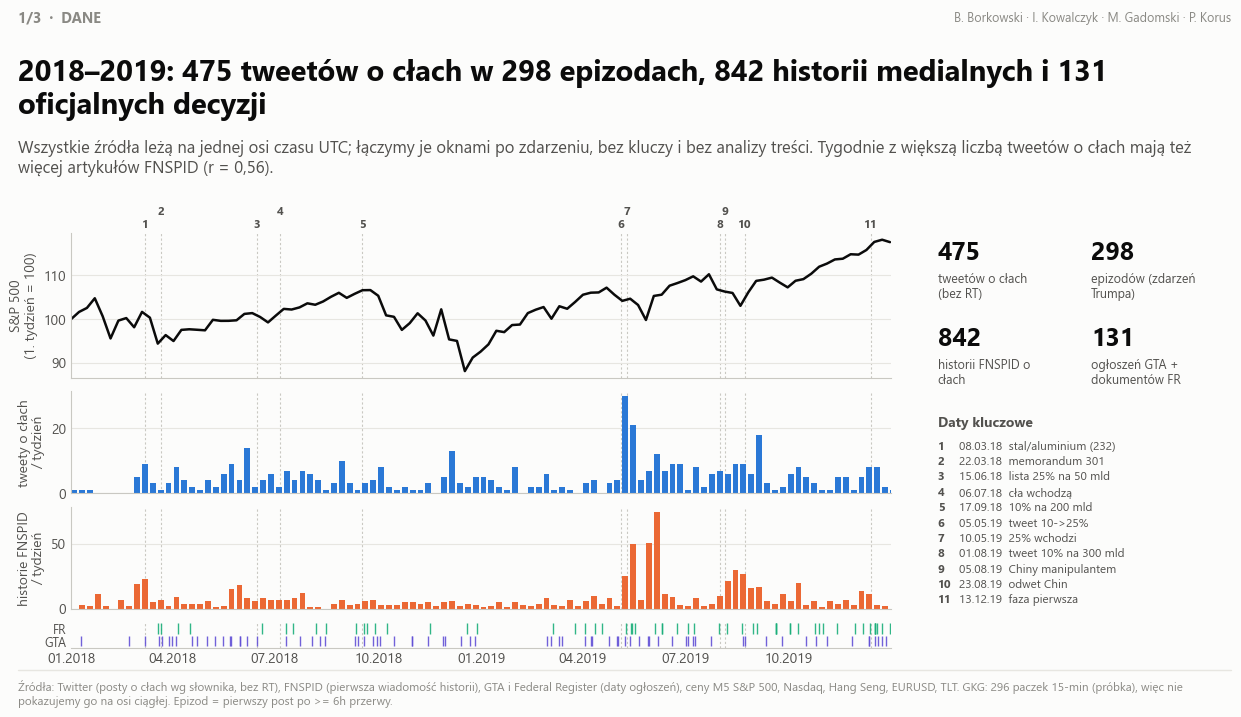

In [10]:
# SLAJD 1 / 3 — co jest w danych: oś czasu 2018-2019, tweety, media, decyzje, rynek
MAIN = "S&P 500" if "S&P 500" in res["prices"] else list(res["prices"])[0]
fig1 = pkg.slides.slide_data(res, main=MAIN)

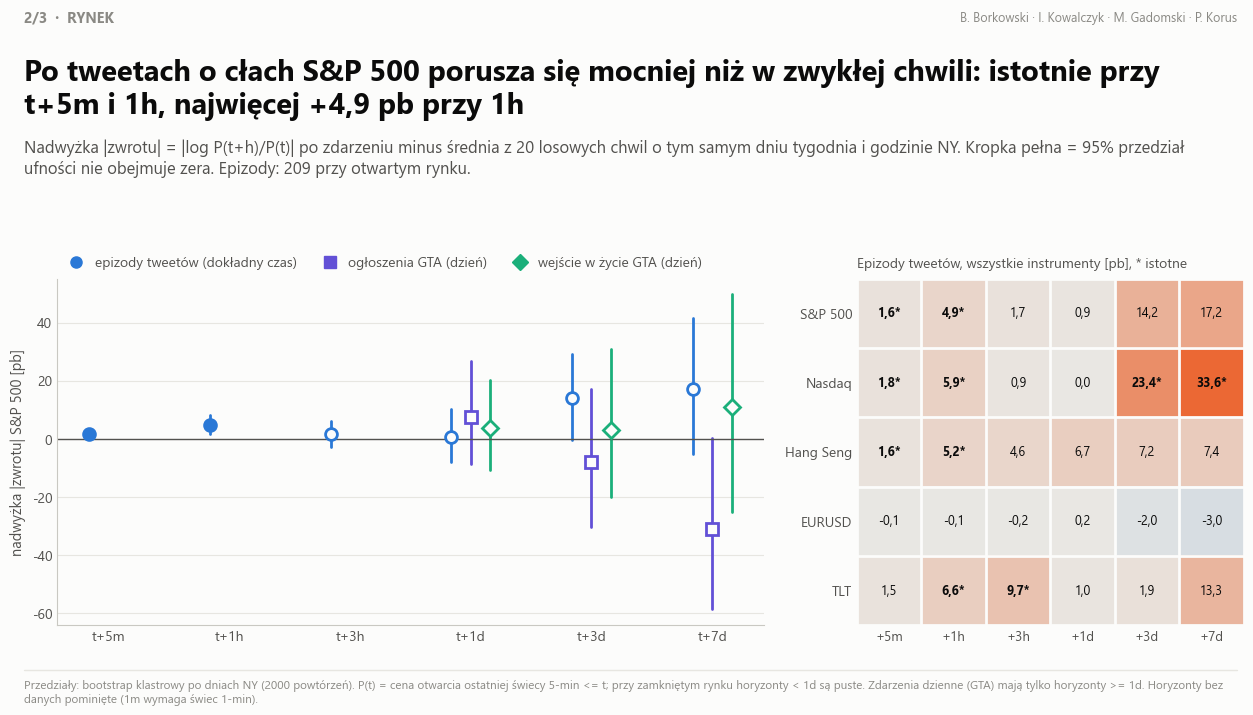

In [11]:
# SLAJD 2 / 3 — czy rynek reaguje na tweety mocniej niż w zwykłej chwili (placebo) i czy szybciej niż na decyzje GTA
fig2 = pkg.slides.slide_market(res, main=MAIN)

python-pptx niedostępny: zapisano PNG i PDF (pip install python-pptx, żeby dostać .pptx).
{'png': ['slajdy\\slajdy_dane_1.png', 'slajdy\\slajdy_dane_2.png', 'slajdy\\slajdy_dane_3.png'], 'pdf': 'slajdy\\slajdy_dane.pdf'}


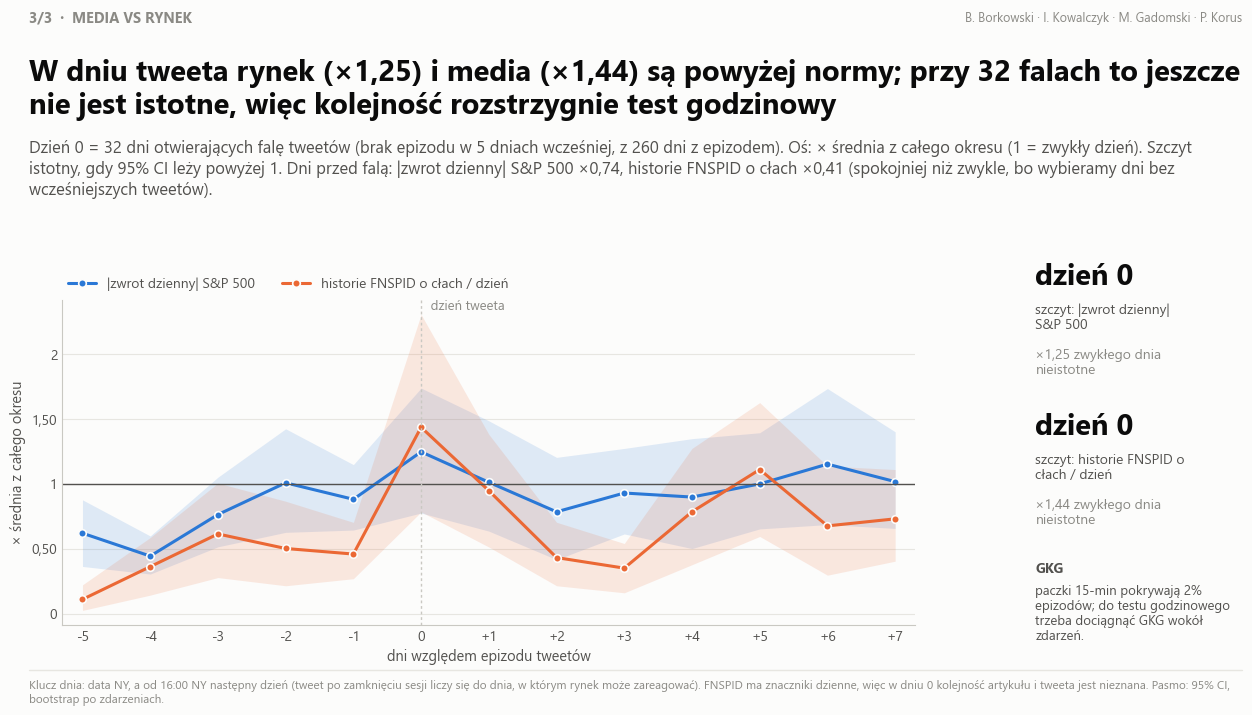

In [12]:
# SLAJD 3 / 3 — kto pierwszy: rynek czy media (profil dni wokół epizodów tweetów) + zapis całości
fig3 = pkg.slides.slide_media(res, main=MAIN)
out = pkg.slides.save_deck([fig1, fig2, fig3], "slajdy")
print({k: [str(p) for p in v] if isinstance(v, list) else str(v) for k, v in out.items()})